In [4]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv("IMDB Dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (50000, 2)


In [6]:
print("Columns:")
print(df.columns)

print("\nDataset information:")
print(df.info())

Columns:
Index(['review', 'sentiment'], dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB
None


In [10]:
import nltk

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...


NLTK resources downloaded successfully!


[nltk_data]   Package omw-1.4 is already up-to-date!


In [11]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

print("NLP preprocessing tools ready!")

NLP preprocessing tools ready!


In [12]:
def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()
    
    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)
    
    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    
    # Tokenization
    tokens = word_tokenize(text)
    
    # Stop-word removal
    tokens = [word for word in tokens if word not in stop_words]
    
    # Lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    
    return ' '.join(tokens)

In [15]:
df['cleaned_review'] = df['review'].apply(preprocess_text)

df[['review', 'cleaned_review', 'sentiment']].head()

,review,cleaned_review,sentiment
0,One of the other reviewers has mentioned that ...,one reviewer mentioned watching oz episode hoo...,positive
1,A wonderful little production. <br /><br />The...,wonderful little production filming technique ...,positive
2,I thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...,positive
3,Basically there's a family where a little boy ...,basically family little boy jake think zombie ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei love time money visually stunnin...,positive


In [16]:
X = df['cleaned_review']
y = df['sentiment']

print("Features:", X.shape)
print("Labels:", y.shape)

Features: (50000,)
Labels: (50000,)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 40000
Testing samples: 10000


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [19]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape:", X_test_tfidf.shape)

TF-IDF training shape: (40000, 10000)
TF-IDF testing shape: (10000, 10000)


In [20]:
from sklearn.svm import LinearSVC

model = LinearSVC()

model.fit(X_train_tfidf, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [21]:
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")
print("First 10 predictions:")
print(y_pred[:10])

Predictions completed!
First 10 predictions:
['negative' 'negative' 'positive' 'negative' 'negative' 'negative'
 'negative' 'negative' 'negative' 'negative']


In [22]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("SVM Accuracy:", round(accuracy * 100, 2), "%")

SVM Accuracy: 89.13 %


In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.90      0.89      0.89      5000
    positive       0.89      0.90      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



In [24]:
def predict_sentiment(review):
    cleaned_review = preprocess_text(review)
    review_tfidf = tfidf.transform([cleaned_review])
    prediction = model.predict(review_tfidf)[0]
    
    return prediction

In [25]:
reviews = [
    "This movie was absolutely amazing and I loved every moment of it.",
    "The movie was boring, disappointing and a complete waste of time.",
    "I really enjoyed this film. The story was excellent."
]

for review in reviews:
    prediction = predict_sentiment(review)
    print("Review:", review)
    print("Predicted Sentiment:", prediction)
    print("-" * 60)

Review: This movie was absolutely amazing and I loved every moment of it.
Predicted Sentiment: positive
------------------------------------------------------------
Review: The movie was boring, disappointing and a complete waste of time.
Predicted Sentiment: negative
------------------------------------------------------------
Review: I really enjoyed this film. The story was excellent.
Predicted Sentiment: positive
------------------------------------------------------------


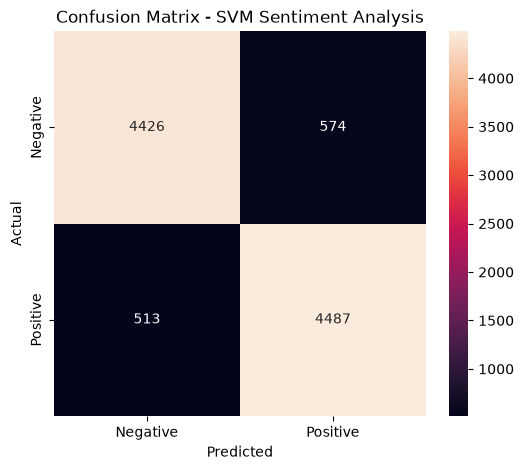

In [26]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=['negative', 'positive'])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVM Sentiment Analysis')
plt.show()

In [27]:
print("=" * 60)
print("PROJECT 4 - NLP & SENTIMENT ANALYSIS")
print("=" * 60)

print("Dataset:", "IMDB Movie Reviews")
print("Total reviews:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("TF-IDF features:", X_train_tfidf.shape[1])
print("Model:", "Linear SVM")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Preprocessing:", "Tokenization, Stop-word Removal, Lemmatization")
print("=" * 60)

PROJECT 4 - NLP & SENTIMENT ANALYSIS
Dataset: IMDB Movie Reviews
Total reviews: 50000
Training samples: 40000
Testing samples: 10000
TF-IDF features: 10000
Model: Linear SVM
Accuracy: 89.13 %
Preprocessing: Tokenization, Stop-word Removal, Lemmatization
